# A2 — Healthcare- Can a Quantum Model Spot Tumours?

Vivekananda GN

**Data:** the classic Breast Cancer Wisconsin dataset (569 patients, 30 measurements from cell images; included in scikit-learn).

**Model:** a 4-qubit quantum kernel + SVM.

**Is it true:** quantum is claimed to help when *data is scarce*. Is that true here?

In [ ]:
# Run once (Google Colab or local). Qibo = open-source quantum simulator (qibo.science)
!pip install -q qibo scikit-learn matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.5/369.5 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 12.2 MB/s eta 0:00:00


In [ ]:
import numpy as np, matplotlib.pyplot as plt
from qibo import Circuit, gates, set_backend
set_backend("numpy")
np.set_printoptions(precision=3, suppress=True)
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, recall_score

[Qibo 0.3.5|INFO|2026-10-03 04:09:34]: Using numpy backend on /CPU:0
INFO:qibo.config:Using numpy backend on /CPU:0


In [ ]:
def feature_state(x, n=4, scale=1.0, reps=2):
    c = Circuit(n)
    for _ in range(reps):
        for q in range(n):
            c.add(gates.H(q)); c.add(gates.RY(q, scale * x[q]))
        for q in range(n - 1): c.add(gates.CNOT(q, q + 1))
        for q in range(n): c.add(gates.RZ(q, scale * x[q]))
        for q in range(n - 1): c.add(gates.CNOT(q, q + 1))
    return np.array(c().state())

def quantum_kernel(A, B, **kw):
    SA = np.array([feature_state(a, **kw) for a in A]); SB = np.array([feature_state(b, **kw) for b in B])
    return np.abs(SA.conj() @ SB.T) ** 2          # similarity of two quantum states (1 = identical)

## 1. Prepare the data: 30 measurements → 4 numbers → 4 qubits

In [ ]:
D = load_breast_cancer()
X, y = D.data, D.target                       # y: 0 = malignant, 1 = benign
Xtr_all, Xte, ytr_all, yte = train_test_split(X, y, test_size=100, random_state=0, stratify=y)
pre_s, pre_p = StandardScaler().fit(Xtr_all), None
pca = PCA(4).fit(pre_s.transform(Xtr_all))
sc = MinMaxScaler((0, np.pi)).fit(pca.transform(pre_s.transform(Xtr_all)))
prep = lambda A: np.clip(sc.transform(pca.transform(pre_s.transform(A))), 0, np.pi)
print("patients for training:", len(Xtr_all), " | held-out test patients:", len(Xte))

patients for training: 469  | held-out test patients: 100


## 2. Train on 80 patients, test on 100 unseen patients

Quantum-kernel SVM accuracy: 0.90 | catches 76% of malignant cases
Classical RBF SVM accuracy : 0.92 | catches 86% of malignant cases


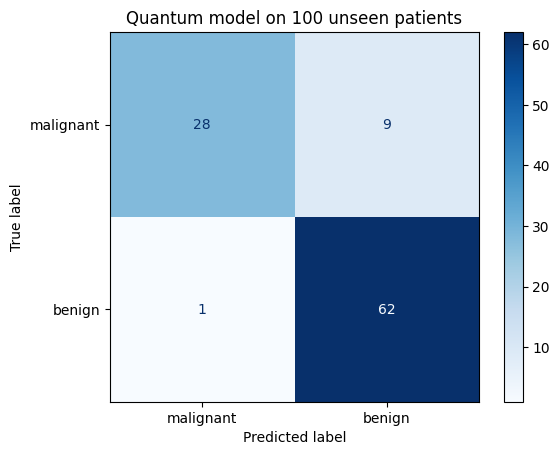

In [ ]:
rng = np.random.default_rng(0)
idx = rng.choice(len(Xtr_all), 80, replace=False)
A, ya = prep(Xtr_all[idx]), ytr_all[idx]; B = prep(Xte)
Kq = quantum_kernel(A, A, scale=0.5); Kqt = quantum_kernel(B, A, scale=0.5)
q = SVC(kernel='precomputed').fit(Kq, ya)
pred = q.predict(Kqt)
print(f"Quantum-kernel SVM accuracy: {np.mean(pred == yte):.2f} | catches {recall_score(yte, pred, pos_label=0):.0%} of malignant cases")
rbf = SVC().fit(A, ya)
print(f"Classical RBF SVM accuracy : {rbf.score(B, yte):.2f} | catches {recall_score(yte, rbf.predict(B), pos_label=0):.0%} of malignant cases")
ConfusionMatrixDisplay.from_predictions(yte, pred, display_labels=['malignant', 'benign'], cmap='Blues'); plt.title('Quantum model on 100 unseen patients'); plt.show()

## 3. Check: a few individual 'patients'

In [ ]:
names = {0: 'MALIGNANT', 1: 'benign'}
for i in range(8):
    flag = 'OK ' if pred[i] == yte[i] else 'MISS'
    print(f"patient {i}: true = {names[yte[i]]:<9} | quantum model says {names[pred[i]]:<9} [{flag}]")

patient 0: true = benign    | quantum model says benign    [OK ]
patient 1: true = benign    | quantum model says benign    [OK ]
patient 2: true = benign    | quantum model says benign    [OK ]
patient 3: true = MALIGNANT | quantum model says MALIGNANT [OK ]
patient 4: true = benign    | quantum model says benign    [OK ]
patient 5: true = benign    | quantum model says benign    [OK ]
patient 6: true = benign    | quantum model says benign    [OK ]
patient 7: true = benign    | quantum model says benign    [OK ]


## 4. experiment: does quantum help when data is scarce?
Train on 10, 20, 40, 80 patients (5 random draws each) and compare.

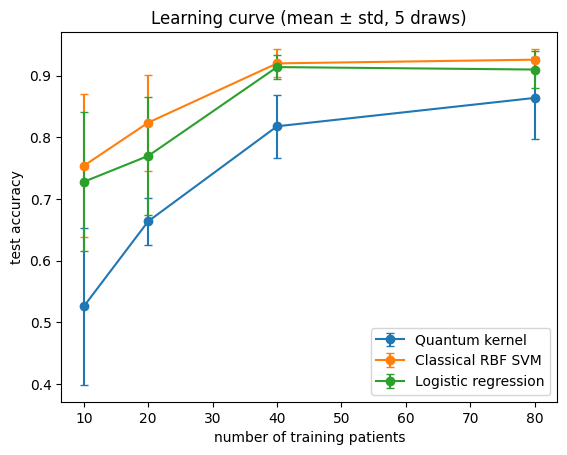

Quantum kernel       ['0.53', '0.66', '0.82', '0.86']
Classical RBF SVM    ['0.75', '0.82', '0.92', '0.93']
Logistic regression  ['0.73', '0.77', '0.91', '0.91']


In [ ]:
sizes = [10, 20, 40, 80]
res = {'Quantum kernel': [], 'Classical RBF SVM': [], 'Logistic regression': []}
for n in sizes:
    r = {k: [] for k in res}
    for s in range(5):
        ii = np.random.default_rng(100 + s).choice(len(Xtr_all), n, replace=False)
        yy = ytr_all[ii]
        if len(set(yy)) < 2: yy[0] = 1 - yy[0]
        Aa = prep(Xtr_all[ii])
        r['Quantum kernel'].append(SVC(kernel='precomputed').fit(quantum_kernel(Aa, Aa, scale=0.5), yy).score(quantum_kernel(B, Aa, scale=0.5), yte))
        r['Classical RBF SVM'].append(SVC().fit(Aa, yy).score(B, yte))
        r['Logistic regression'].append(LogisticRegression().fit(Aa, yy).score(B, yte))
    for k in res: res[k].append((np.mean(r[k]), np.std(r[k])))
for k, v in res.items():
    m, s = zip(*v); plt.errorbar(sizes, m, yerr=s, marker='o', capsize=3, label=k)
plt.xlabel('number of training patients'); plt.ylabel('test accuracy'); plt.legend(); plt.title('Learning curve (mean ± std, 5 draws)'); plt.show()
for k, v in res.items(): print(f"{k:<20}", [f"{m:.2f}" for m, s in v])

## 5. Observations & Discussions
* Look at the curves: is the quantum model clearly above the classical ones, anywhere? Report what the data says, not what we hoped. (In our test run the classical models were ahead at every training size, especially with very few patients.)
* **Accuracy is not enough in medicine:** see how many *malignant* cases were missed (recall). A model with good accuracy can still miss too many cancers.
* Why do researchers still study this? Small-data regimes and structured data are where theory suggests possible benefits; evidence is still mixed.

* **Try:** change `scale` (0.25, 1.0), use 3 or 5 PCA components (also change qubits `n`), or try the `load_wine` dataset.